# Project 27: Insurance Claims & Settlement Analysis

**Industry:** Insurance / Financial Services  
**Dataset:** `data/27_insurance_claims.csv`

## Business objective
Study insurance claims, claim amounts, claim types and settlement status to understand claim patterns and processing performance.

## Project workflow
This notebook completes all 15 assignment tasks, produces summary tables and charts, and saves analysis outputs in the `outputs/` folder.

### Dataset handling decisions
- Duplicate `Claim_ID` records are identified and removed by keeping the first occurrence. The supplied duplicates are exact repeated records.
- Missing `Claim_Amount` and `Settlement_Days` values are filled with their respective median values. The median is robust to unusually high or low values.
- Approval percentage uses **decided claims only** (Approved + Rejected), excluding Pending claims from the denominator.
- Approved settlement statistics use approved claims only, as required by the assignment hint.
- Claim amount bands use transparent fixed thresholds: Small < 100,000; Medium 100,000 to < 300,000; Large >= 300,000. Adjust these if your instructor provides different ranges.
- IQR outliers are statistical flags for review, not evidence of fraud or error.

> Run the notebook from top to bottom. The notebook expects the CSV in the included `data/` folder.

## 0. Import libraries and set up folders

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "27_insurance_claims.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"

OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR.resolve())
print("Dataset found:", DATA_PATH.exists())

Project folder: /mnt/data/insurance_claims_analysis
Dataset found: True


## Task 1. Load and inspect the dataset

In [2]:
df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nFirst five rows:")
display(df_raw.head())
print("\nData types:")
display(df_raw.dtypes.to_frame("Data_Type"))
print("\nNumerical summary:")
display(df_raw.describe())
print("\nCategorical summary:")
display(df_raw.describe(include="object"))

Dataset shape: (761, 8)

Column names:
['Claim_ID', 'Claim_Date', 'Insurance_Type', 'Claim_Type', 'Claim_Amount', 'Settlement_Days', 'Claim_Status', 'Customer_ID']

First five rows:


,Claim_ID,Claim_Date,Insurance_Type,Claim_Type,Claim_Amount,Settlement_Days,Claim_Status,Customer_ID
0,CL000000,2026-09-17,Motor,Medical,"393,052.81",117.00,Approved,CUS00060
1,CL000001,2026-03-19,Property,Other,"268,590.57",2.00,Rejected,CUS00254
2,CL000002,2025-08-09,Health,Theft,"320,110.30",63.00,Rejected,CUS00010
3,CL000003,2025-08-09,Property,Medical,"488,247.47",69.00,Approved,CUS00433
4,CL000004,2026-08-11,Motor,Loss,"483,651.10",94.00,Approved,CUS00161



Data types:


,Data_Type
Claim_ID,object
Claim_Date,object
Insurance_Type,object
Claim_Type,object
Claim_Amount,float64
Settlement_Days,float64
Claim_Status,object
Customer_ID,object



Numerical summary:


,Claim_Amount,Settlement_Days
count,743.00,743.00
mean,"248,120.60",61.02
std,"146,563.62",34.86
min,"2,513.94",1.00
25%,"120,342.90",30.50
50%,"249,149.29",62.00
75%,"373,101.59",91.00
max,"499,442.63",119.00



Categorical summary:


,Claim_ID,Claim_Date,Insurance_Type,Claim_Type,Claim_Status,Customer_ID
count,761,761,761,761,761,761
unique,750,459,5,6,3,386
top,CL000155,2025-06-08,Travel,Loss,Approved,CUS00028
freq,2,6,166,132,514,7


## Task 2. Identify missing values and duplicate Claim_ID records

In [3]:
missing_summary = df_raw.isna().sum().to_frame("Missing_Count")
missing_summary["Missing_Percentage"] = (missing_summary["Missing_Count"] / len(df_raw) * 100).round(2)

duplicate_id_count = df_raw.duplicated(subset="Claim_ID").sum()
duplicate_id_rows = df_raw[df_raw.duplicated(subset="Claim_ID", keep=False)].sort_values("Claim_ID")

print("Missing-value summary:")
display(missing_summary)
print(f"Duplicate Claim_ID rows beyond the first occurrence: {duplicate_id_count}")
print("Rows involved in duplicated Claim_IDs:")
display(duplicate_id_rows)

Missing-value summary:


,Missing_Count,Missing_Percentage
Claim_ID,0,0.00
Claim_Date,0,0.00
Insurance_Type,0,0.00
Claim_Type,0,0.00
Claim_Amount,18,2.37
Settlement_Days,18,2.37
Claim_Status,0,0.00
Customer_ID,0,0.00


Duplicate Claim_ID rows beyond the first occurrence: 11
Rows involved in duplicated Claim_IDs:


,Claim_ID,Claim_Date,Insurance_Type,Claim_Type,Claim_Amount,Settlement_Days,Claim_Status,Customer_ID
97,CL000097,2025-10-29,Life,Medical,"2,513.94",38.00,Approved,CUS00348
760,CL000097,2025-10-29,Life,Medical,"2,513.94",38.00,Approved,CUS00348
133,CL000133,2025-11-25,Property,Damage,"478,473.08",91.00,Approved,CUS00442
752,CL000133,2025-11-25,Property,Damage,"478,473.08",91.00,Approved,CUS00442
155,CL000155,2026-09-01,Life,Theft,"198,735.51",119.00,Approved,CUS00286
757,CL000155,2026-09-01,Life,Theft,"198,735.51",119.00,Approved,CUS00286
250,CL000250,2025-11-23,Travel,Damage,"473,970.39",91.00,Approved,CUS00004
753,CL000250,2025-11-23,Travel,Damage,"473,970.39",91.00,Approved,CUS00004
299,CL000299,2025-07-06,Property,Accident,"74,221.87",102.00,Pending,CUS00446
754,CL000299,2025-07-06,Property,Accident,"74,221.87",102.00,Pending,CUS00446


## Task 3. Handle missing Claim_Amount and Settlement_Days values

In [4]:
# Remove repeated Claim_ID records, keeping the first record for each ID.
df = df_raw.drop_duplicates(subset="Claim_ID", keep="first").copy()

# Convert the two numeric columns safely, then impute missing values with medians.
for col in ["Claim_Amount", "Settlement_Days"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)
    print(f"{col}: missing values filled with median = {median_value:,.2f}")

print("\nShape before duplicate removal:", df_raw.shape)
print("Shape after duplicate removal and imputation:", df.shape)
print("\nRemaining missing values:")
display(df.isna().sum().to_frame("Missing_Count"))

Claim_Amount: missing values filled with median = 249,801.57
Settlement_Days: missing values filled with median = 61.00

Shape before duplicate removal: (761, 8)
Shape after duplicate removal and imputation: (750, 8)

Remaining missing values:


,Missing_Count
Claim_ID,0
Claim_Date,0
Insurance_Type,0
Claim_Type,0
Claim_Amount,0
Settlement_Days,0
Claim_Status,0
Customer_ID,0


## Task 4. Convert Claim_Date to datetime and extract month and year

In [5]:
df["Claim_Date"] = pd.to_datetime(df["Claim_Date"], errors="coerce")
df["Claim_Year"] = df["Claim_Date"].dt.year
df["Claim_Month"] = df["Claim_Date"].dt.month
df["Claim_Month_Name"] = df["Claim_Date"].dt.month_name()
df["Claim_Year_Month"] = df["Claim_Date"].dt.to_period("M").astype(str)

print("Claim_Date data type:", df["Claim_Date"].dtype)
display(df[["Claim_ID", "Claim_Date", "Claim_Year", "Claim_Month", "Claim_Month_Name"]].head(10))
print("Invalid/missing dates after conversion:", df["Claim_Date"].isna().sum())

Claim_Date data type: datetime64[ns]


,Claim_ID,Claim_Date,Claim_Year,Claim_Month,Claim_Month_Name
0,CL000000,2026-09-17,2026,9,September
1,CL000001,2026-03-19,2026,3,March
2,CL000002,2025-08-09,2025,8,August
3,CL000003,2025-08-09,2025,8,August
4,CL000004,2026-08-11,2026,8,August
5,CL000005,2025-11-29,2025,11,November
6,CL000006,2025-07-09,2025,7,July
7,CL000007,2025-09-18,2025,9,September
8,CL000008,2025-06-27,2025,6,June
9,CL000009,2026-08-28,2026,8,August


Invalid/missing dates after conversion: 0


## Task 5. Calculate total claims, approved claims, rejected claims and approval percentage

In [6]:
status_counts = df["Claim_Status"].value_counts().reindex(["Approved", "Rejected", "Pending"], fill_value=0)
total_claims = len(df)
approved_claims = int(status_counts.get("Approved", 0))
rejected_claims = int(status_counts.get("Rejected", 0))
pending_claims = int(status_counts.get("Pending", 0))
decided_claims = approved_claims + rejected_claims
approval_percentage = (approved_claims / decided_claims * 100) if decided_claims else np.nan

claim_status_summary = pd.DataFrame({
    "Metric": ["Total Claims", "Approved Claims", "Rejected Claims", "Pending Claims",
               "Decided Claims", "Approval Percentage (of decided claims)"],
    "Value": [total_claims, approved_claims, rejected_claims, pending_claims,
              decided_claims, round(approval_percentage, 2)]
})
display(claim_status_summary)

,Metric,Value
0,Total Claims,750.00
1,Approved Claims,506.00
2,Rejected Claims,123.00
3,Pending Claims,121.00
4,Decided Claims,629.00
5,Approval Percentage (of decided claims),80.45


## Task 6. Calculate total and average claim amount for approved claims

In [7]:
approved_df = df[df["Claim_Status"].eq("Approved")].copy()
approved_total_amount = approved_df["Claim_Amount"].sum()
approved_average_amount = approved_df["Claim_Amount"].mean()

approved_amount_summary = pd.DataFrame({
    "Metric": ["Number of Approved Claims", "Total Approved Claim Amount", "Average Approved Claim Amount"],
    "Value": [len(approved_df), approved_total_amount, approved_average_amount]
})
display(approved_amount_summary)

,Metric,Value
0,Number of Approved Claims,506.00
1,Total Approved Claim Amount,"124,360,544.16"
2,Average Approved Claim Amount,"245,771.83"


## Task 7. Rank insurance types by number of claims and total claim amount

In [8]:
insurance_ranking = (
    df.groupby("Insurance_Type")
      .agg(Number_of_Claims=("Claim_ID", "count"),
           Total_Claim_Amount=("Claim_Amount", "sum"),
           Average_Claim_Amount=("Claim_Amount", "mean"))
      .sort_values(["Number_of_Claims", "Total_Claim_Amount"], ascending=False)
      .reset_index()
)
insurance_ranking["Claim_Count_Rank"] = insurance_ranking["Number_of_Claims"].rank(method="min", ascending=False).astype(int)
insurance_ranking["Total_Amount_Rank"] = insurance_ranking["Total_Claim_Amount"].rank(method="min", ascending=False).astype(int)
display(insurance_ranking)

,Insurance_Type,Number_of_Claims,Total_Claim_Amount,Average_Claim_Amount,Claim_Count_Rank,Total_Amount_Rank
0,Travel,164,"42,276,273.76","257,782.16",1,1
1,Health,152,"37,255,125.62","245,099.51",2,2
2,Property,150,"36,041,110.44","240,274.07",3,3
3,Life,148,"34,872,891.05","235,627.64",4,5
4,Motor,136,"35,952,549.98","264,356.99",5,4


## Task 8. Compare average settlement time across claim types

In [9]:
settlement_by_claim_type = (
    df.groupby("Claim_Type")
      .agg(Average_Settlement_Days=("Settlement_Days", "mean"),
           Median_Settlement_Days=("Settlement_Days", "median"),
           Number_of_Claims=("Claim_ID", "count"))
      .sort_values("Average_Settlement_Days", ascending=False)
      .reset_index()
)
display(settlement_by_claim_type)

,Claim_Type,Average_Settlement_Days,Median_Settlement_Days,Number_of_Claims
0,Loss,65.84,68.00,129
1,Accident,63.71,63.00,125
2,Theft,63.43,62.50,128
3,Medical,61.04,64.00,129
4,Other,57.98,60.00,115
5,Damage,52.19,49.50,124


## Task 9. Analyse approval and rejection percentages by insurance type

In [10]:
insurance_status = pd.crosstab(df["Insurance_Type"], df["Claim_Status"])
for status in ["Approved", "Rejected", "Pending"]:
    if status not in insurance_status.columns:
        insurance_status[status] = 0

decided_by_type = insurance_status["Approved"] + insurance_status["Rejected"]
insurance_status["Approval_Percentage"] = np.where(decided_by_type > 0, insurance_status["Approved"] / decided_by_type * 100, np.nan)
insurance_status["Rejection_Percentage"] = np.where(decided_by_type > 0, insurance_status["Rejected"] / decided_by_type * 100, np.nan)
insurance_status = insurance_status.reset_index()
display(insurance_status)

Claim_Status,Insurance_Type,Approved,Pending,Rejected,Approval_Percentage,Rejection_Percentage
0,Health,99,25,28,77.95,22.05
1,Life,102,21,25,80.31,19.69
2,Motor,96,22,18,84.21,15.79
3,Property,102,25,23,81.60,18.40
4,Travel,107,28,29,78.68,21.32


## Task 10. Identify the 10 highest-value claims

In [11]:
top_10_claims = df.nlargest(10, "Claim_Amount")[
    ["Claim_ID", "Customer_ID", "Insurance_Type", "Claim_Type", "Claim_Amount", "Claim_Status", "Claim_Date"]
].reset_index(drop=True)
display(top_10_claims)

,Claim_ID,Customer_ID,Insurance_Type,Claim_Type,Claim_Amount,Claim_Status,Claim_Date
0,CL000209,CUS00181,Life,Medical,"499,442.63",Approved,2025-06-08
1,CL000475,CUS00049,Life,Accident,"499,200.44",Approved,2025-05-07
2,CL000141,CUS00062,Life,Accident,"498,956.30",Approved,2026-05-03
3,CL000077,CUS00398,Travel,Damage,"498,828.66",Approved,2025-07-02
4,CL000546,CUS00085,Travel,Theft,"498,721.83",Approved,2026-06-07
5,CL000589,CUS00133,Health,Medical,"498,611.73",Approved,2026-10-18
6,CL000320,CUS00125,Life,Loss,"498,416.53",Rejected,2025-10-31
7,CL000117,CUS00401,Health,Medical,"498,016.11",Approved,2026-09-14
8,CL000005,CUS00243,Property,Theft,"497,407.87",Pending,2025-11-29
9,CL000511,CUS00052,Motor,Damage,"496,788.69",Approved,2025-01-15


## Task 11. Use a set for unique claim categories and a dictionary for claim counts by status

In [12]:
unique_claim_categories = set(df["Claim_Type"].dropna().unique())
claim_counts_by_status = df["Claim_Status"].value_counts().to_dict()

print("Unique claim categories:")
print(unique_claim_categories)
print("\nClaim counts by status (dictionary):")
print(claim_counts_by_status)

Unique claim categories:
{'Medical', 'Accident', 'Damage', 'Theft', 'Other', 'Loss'}

Claim counts by status (dictionary):
{'Approved': 506, 'Rejected': 123, 'Pending': 121}


## Task 12. Create a function to classify claim amounts as Small, Medium or Large

In [13]:
def classify_claim_amount(amount):
    """Classify a claim amount using fixed, documented rupee/value bands."""
    if pd.isna(amount):
        return "Unknown"
    if amount < 100_000:
        return "Small"
    elif amount < 300_000:
        return "Medium"
    return "Large"

df["Claim_Size_Category"] = df["Claim_Amount"].apply(classify_claim_amount)
claim_size_summary = (
    df["Claim_Size_Category"]
      .value_counts()
      .reindex(["Small", "Medium", "Large", "Unknown"], fill_value=0)
      .rename_axis("Claim_Size_Category")
      .reset_index(name="Number_of_Claims")
)
display(claim_size_summary)

,Claim_Size_Category,Number_of_Claims
0,Small,163
1,Medium,297
2,Large,290
3,Unknown,0


## Task 13. Use NumPy to calculate mean, median and standard deviation of claim amounts

In [14]:
claim_amount_array = df["Claim_Amount"].dropna().to_numpy()

numpy_statistics = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Standard Deviation (population)", "Minimum", "Maximum"],
    "Value": [
        np.mean(claim_amount_array),
        np.median(claim_amount_array),
        np.std(claim_amount_array),
        np.min(claim_amount_array),
        np.max(claim_amount_array)
    ]
})
display(numpy_statistics)

,Statistic,Value
0,Mean,"248,530.60"
1,Median,"249,801.57"
2,Standard Deviation (population),"144,264.45"
3,Minimum,"2,513.94"
4,Maximum,"499,442.63"


## Task 14. Identify unusually high claim amounts using IQR and compare average settlement days by claim status

In [15]:
q1 = df["Claim_Amount"].quantile(0.25)
q3 = df["Claim_Amount"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

high_claim_outliers = df[df["Claim_Amount"] > upper_bound].sort_values("Claim_Amount", ascending=False)

print(f"Q1: {q1:,.2f}")
print(f"Q3: {q3:,.2f}")
print(f"IQR: {iqr:,.2f}")
print(f"Upper outlier boundary: {upper_bound:,.2f}")
print(f"Number of unusually high claims: {len(high_claim_outliers)}")
display(high_claim_outliers[["Claim_ID", "Insurance_Type", "Claim_Type", "Claim_Amount", "Claim_Status"]].head(20))

settlement_by_status = (
    df.groupby("Claim_Status")
      .agg(Average_Settlement_Days=("Settlement_Days", "mean"),
           Median_Settlement_Days=("Settlement_Days", "median"),
           Number_of_Claims=("Claim_ID", "count"))
      .reset_index()
)
print("Settlement days by claim status:")
display(settlement_by_status)

Q1: 122,367.24
Q3: 371,144.10
IQR: 248,776.86
Upper outlier boundary: 744,309.40
Number of unusually high claims: 0


,Claim_ID,Insurance_Type,Claim_Type,Claim_Amount,Claim_Status


Settlement days by claim status:


,Claim_Status,Average_Settlement_Days,Median_Settlement_Days,Number_of_Claims
0,Approved,59.33,61.00,506
1,Pending,63.43,67.00,121
2,Rejected,64.15,69.00,123


## Task 15. Create an InsuranceClaim class and write five process-improvement recommendations

In [16]:
class InsuranceClaim:
    """A simple representation of one insurance claim."""

    def __init__(self, claim_id, insurance_type, claim_type, claim_amount, claim_status):
        self.claim_id = claim_id
        self.insurance_type = insurance_type
        self.claim_type = claim_type
        self.claim_amount = float(claim_amount)
        self.claim_status = claim_status

    def claim_size(self):
        return classify_claim_amount(self.claim_amount)

    def summary(self):
        return {
            "Claim_ID": self.claim_id,
            "Insurance_Type": self.insurance_type,
            "Claim_Type": self.claim_type,
            "Claim_Amount": self.claim_amount,
            "Claim_Status": self.claim_status,
            "Claim_Size": self.claim_size()
        }

# Demonstrate the class using the first cleaned record.
first_claim = df.iloc[0]
claim_object = InsuranceClaim(
    first_claim["Claim_ID"],
    first_claim["Insurance_Type"],
    first_claim["Claim_Type"],
    first_claim["Claim_Amount"],
    first_claim["Claim_Status"]
)
print("InsuranceClaim class demonstration:")
display(pd.DataFrame([claim_object.summary()]))

# Evidence-based recommendations generated from the analysis.
slowest_claim_type = settlement_by_claim_type.iloc[0]["Claim_Type"]
slowest_days = settlement_by_claim_type.iloc[0]["Average_Settlement_Days"]
largest_insurance_type = insurance_ranking.sort_values("Total_Claim_Amount", ascending=False).iloc[0]["Insurance_Type"]
largest_insurance_total = insurance_ranking.sort_values("Total_Claim_Amount", ascending=False).iloc[0]["Total_Claim_Amount"]
highest_rejection_type = insurance_status.sort_values("Rejection_Percentage", ascending=False).iloc[0]
pending_share = pending_claims / total_claims * 100 if total_claims else 0

recommendations = [
    f"Review the {slowest_claim_type} claims workflow: it has the longest average settlement time ({slowest_days:.1f} days). Map hand-offs and identify documentation or approval bottlenecks.",
    f"Prioritise financial monitoring for {largest_insurance_type}, which has the largest aggregate claim amount ({largest_insurance_total:,.2f}). Use regular reserve and trend reviews.",
    f"Review rejection reasons and customer communication for {highest_rejection_type['Insurance_Type']}; its rejection rate among decided claims is {highest_rejection_type['Rejection_Percentage']:.1f}%.",
    f"Create a pending-claim ageing queue. Pending claims currently represent {pending_share:.1f}% of all records; assign owners and escalation dates to reduce delays.",
    f"Use a high-value claim review checklist for claims above the IQR upper boundary ({upper_bound:,.2f}). These statistical flags should trigger verification, not automatic rejection."
]

print("Five process-improvement recommendations:")
for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

InsuranceClaim class demonstration:


,Claim_ID,Insurance_Type,Claim_Type,Claim_Amount,Claim_Status,Claim_Size
0,CL000000,Motor,Medical,"393,052.81",Approved,Large


Five process-improvement recommendations:
1. Review the Loss claims workflow: it has the longest average settlement time (65.8 days). Map hand-offs and identify documentation or approval bottlenecks.
2. Prioritise financial monitoring for Travel, which has the largest aggregate claim amount (42,276,273.76). Use regular reserve and trend reviews.
3. Review rejection reasons and customer communication for Health; its rejection rate among decided claims is 22.0%.
4. Create a pending-claim ageing queue. Pending claims currently represent 16.1% of all records; assign owners and escalation dates to reduce delays.
5. Use a high-value claim review checklist for claims above the IQR upper boundary (744,309.40). These statistical flags should trigger verification, not automatic rejection.


## Visualisations

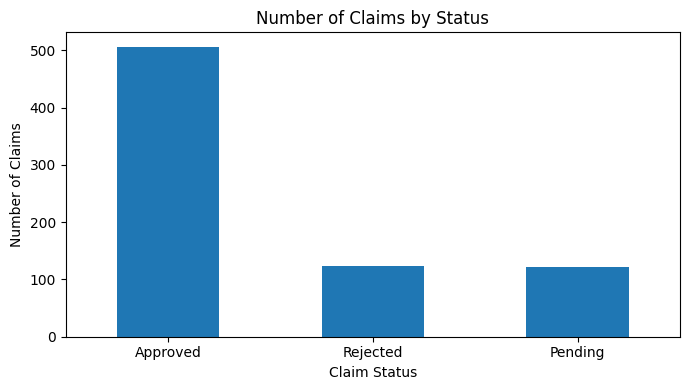

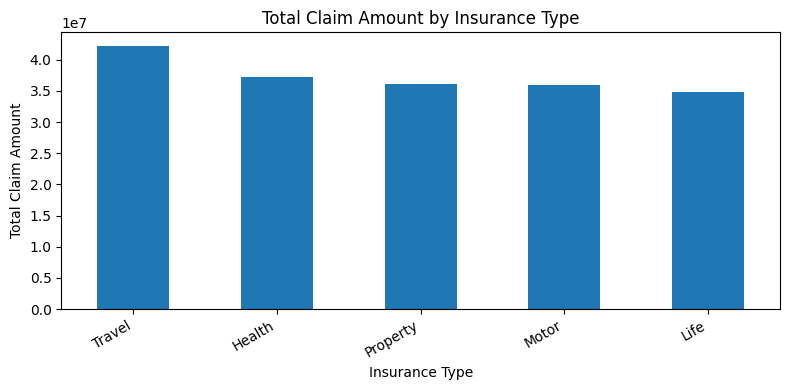

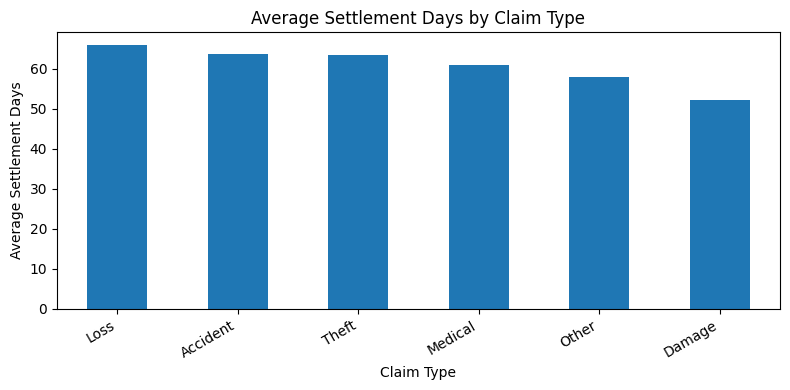

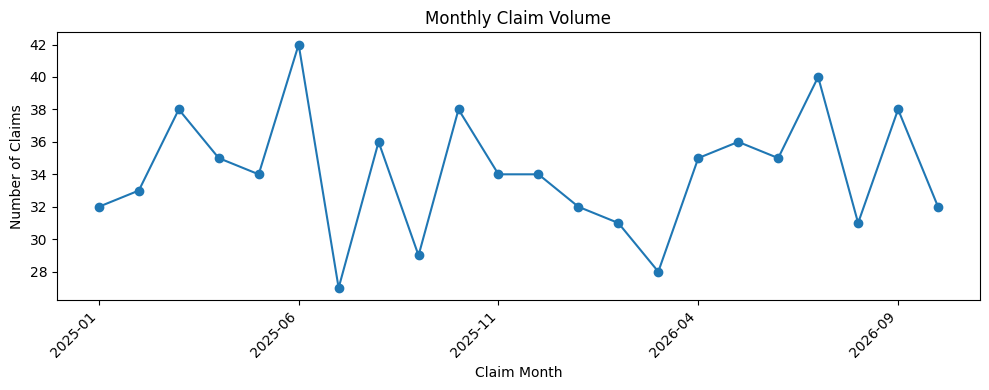

In [17]:
# 1. Claim status counts
status_plot = df["Claim_Status"].value_counts().reindex(["Approved", "Rejected", "Pending"], fill_value=0)
plt.figure(figsize=(7, 4))
status_plot.plot(kind="bar")
plt.title("Number of Claims by Status")
plt.xlabel("Claim Status")
plt.ylabel("Number of Claims")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "claims_by_status.png", dpi=150)
plt.show()

# 2. Total claim amount by insurance type
amount_by_insurance = df.groupby("Insurance_Type")["Claim_Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
amount_by_insurance.plot(kind="bar")
plt.title("Total Claim Amount by Insurance Type")
plt.xlabel("Insurance Type")
plt.ylabel("Total Claim Amount")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "claim_amount_by_insurance_type.png", dpi=150)
plt.show()

# 3. Average settlement days by claim type
plt.figure(figsize=(8, 4))
settlement_by_claim_type.set_index("Claim_Type")["Average_Settlement_Days"].sort_values(ascending=False).plot(kind="bar")
plt.title("Average Settlement Days by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Average Settlement Days")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "settlement_days_by_claim_type.png", dpi=150)
plt.show()

# 4. Monthly claim volume
monthly_claims = df.dropna(subset=["Claim_Date"]).groupby(df.dropna(subset=["Claim_Date"])["Claim_Date"].dt.to_period("M")).size()
plt.figure(figsize=(10, 4))
monthly_claims.index = monthly_claims.index.astype(str)
monthly_claims.plot(kind="line", marker="o")
plt.title("Monthly Claim Volume")
plt.xlabel("Claim Month")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "monthly_claim_volume.png", dpi=150)
plt.show()

## Export key outputs

In [18]:
# Save the cleaned dataset and key assignment deliverables.
df.to_csv(OUTPUT_DIR / "cleaned_insurance_claims.csv", index=False)
claim_status_summary.to_csv(OUTPUT_DIR / "claim_status_summary.csv", index=False)
insurance_ranking.to_csv(OUTPUT_DIR / "insurance_type_ranking.csv", index=False)
settlement_by_claim_type.to_csv(OUTPUT_DIR / "settlement_time_by_claim_type.csv", index=False)
insurance_status.to_csv(OUTPUT_DIR / "approval_rejection_by_insurance_type.csv", index=False)
top_10_claims.to_csv(OUTPUT_DIR / "top_10_high_value_claims.csv", index=False)
high_claim_outliers.to_csv(OUTPUT_DIR / "high_claim_amount_outliers.csv", index=False)
settlement_by_status.to_csv(OUTPUT_DIR / "settlement_time_by_status.csv", index=False)

print("Analysis outputs saved to:", OUTPUT_DIR.resolve())
print("Charts saved to:", CHART_DIR.resolve())

Analysis outputs saved to: /mnt/data/insurance_claims_analysis/outputs
Charts saved to: /mnt/data/insurance_claims_analysis/outputs/charts


## Final conclusion

This notebook has completed all 15 assignment tasks. Review the generated tables and charts before submitting. In particular:
- Explain that approval percentage excludes pending claims.
- Mention that missing numeric values were median-imputed.
- Mention that duplicate Claim_ID records were removed by retaining the first occurrence.
- Treat IQR outliers as records for review, not as confirmed fraud.
- Confirm the claim amount bands with your instructor if they specified different thresholds.